---

# DSC LOGIKA UI 2026: Credit Risk Prediction, v4

*Controlled EDA-driven feature ablations and fold-local preprocessing on Kaggle T4 x2.*

---

## Team Information

- Participant number: fill in before the official notebook submission.
- Team name and members: fill in with the registered team details.

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Integrity and Feature Engineering**](#3)
4. [**Fold-local Preprocessing**](#4)
5. [**Controlled Model Experiments**](#5)
6. [**Ensemble and Stability**](#6)
7. [**Submission and Reproducibility**](#7)

---

# Introduction <a name="1"></a>

---

*Version 4 translates the deep EDA into controlled model comparisons. All reported results below are computed when the notebook runs; no v4 performance has been measured during authoring.*

## Overview

*The target is 90+ DPD within 12 months of origination. Each selected application has its own information cutoff and a unique customer. The dataset combines applications, profiles, repayment, account, bureau, and purchasing histories.*

## Aim

*The experiment tests one nominated spending feature and an explicit pricing representation against the existing feature set. Neural preprocessing is fitted separately within every training fold, and paired comparisons use identical fold membership and seeds.*

## Metric

*The official metric is the two-sided KS statistic. AUC and signed KS are also reported to verify that higher scores represent higher risk. AUC is used for early stopping because single-threshold KS is noisy; AUC improvement does not guarantee KS improvement.*

$$KS=\max_s|F_1(s)-F_0(s)|$$

## Dataset

*Attach the competition dataset containing the eight CSV tables and sample_submission.csv. This notebook reconstructs features from those files and does not require local EDA outputs or earlier model predictions.*

**Attributes**

1. Applications and profiles: affordability, pricing, and demographics.
2. Histories: repayment, account activity, bureau observations, previous applications.
3. E-commerce: orders and order items, with totals aggregated once per order.

**Target**

`target`: 1 for serious repayment difficulty, 0 otherwise.

## Approach

*LightGBM compares raw, spending-only, semantic-only, and combined feature views. TabM, XGBoost, and CatBoost compare raw with combined features. Each model uses five fixed stratified folds and two training seeds. Two independent process queues use GPU 0 and GPU 1.*

*The ensemble uses prespecified family weights. The combined candidate is selected only after a conservative paired OOF check against the baseline. Selection and early stopping still reuse validation labels; the reported scores are diagnostic CV estimates, not untouched-holdout guarantees.*

*Foundation models are excluded from this controlled v4 experiment. The earlier TabPFN result did not establish an ensemble gain, and TabPFN-Rel requires a separate task adapter to preserve per-application cutoffs.*

*Earlier saved v3 OOF KS was 0.51423 for the blend, 0.51259 for TabM, 0.51176 for LightGBM, and 0.49952 for TabPFN. These are historical observations, not v4 results or evidence that foundation models always lose.*

---

# Initialization <a name="2"></a>

---

The notebook requires Kaggle with GPU T4 x2 and Internet enabled for package installation. Use Save Version / Run All after attaching the competition data; runtime is measured during execution and has not been benchmarked for this version.

## Environment Setup

The following cells inspect the assigned GPUs and install the model libraries. The first cell stops execution outside Kaggle.

In [1]:
assert __import__('pathlib').Path('/kaggle/input').is_dir(), 'This notebook is Kaggle-only. Do not run locally.'
!nvidia-smi

Wed Oct 14 00:17:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

The following cell installs the libraries required by this notebook without replacing the Kaggle PyTorch installation.

In [2]:
%pip install -q "polars==2.0.0" "lightgbm==4.6.0" "xgboost==3.0.5" "catboost==1.2.8" "tabm==0.0.3" "rtdl_num_embeddings==0.0.12" "joblib>=1.4,<2"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.6/876.6 kB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.9/94.9 MB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 38.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-polars-cu12 26.2.1 requires polars<1.36,>=1.30, but you have polars 2.0.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Imports are centralized here. Runtime versions are recorded with the outputs.

In [3]:
import gc
import hashlib
import importlib.metadata
import json
import os
import pickle
import random
import time
import warnings
from pathlib import Path

os.environ["POLARS_MAX_THREADS"] = "4"
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import torch
import lightgbm as lgb
import xgboost as xgb
import tabm
import rtdl_num_embeddings
from catboost import CatBoostClassifier, Pool
from joblib import Parallel, delayed, parallel_config
import scipy.special as scipy_special
from scipy.stats import ks_2samp, rankdata
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore", message="The .*feature has just two bin edges.*", module="rtdl_num_embeddings")
assert torch.cuda.is_available() and torch.cuda.device_count() >= 2, "Select Kaggle GPU T4 x2."
VERSIONS = {name: importlib.metadata.version(name) for name in
            ["numpy", "pandas", "polars", "scipy", "scikit-learn", "torch", "lightgbm",
             "xgboost", "catboost", "tabm", "rtdl_num_embeddings", "joblib"]}
print(VERSIONS)
print([torch.cuda.get_device_name(i) for i in range(2)])

{'numpy': '2.1.3', 'pandas': '2.3.3', 'polars': '2.0.0', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'torch': '2.11.0+cu128', 'lightgbm': '4.6.0', 'xgboost': '3.0.5', 'catboost': '1.2.8', 'tabm': '0.0.3', 'rtdl_num_embeddings': '0.0.12', 'joblib': '1.6.0'}
['Tesla T4', 'Tesla T4']


## Seed Everything

The model seeds vary while the validation assignment remains fixed for paired comparisons. GPU training can retain small numerical nondeterminism.

In [4]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)

## Settings

The default run performs 100 fold fits: 40 LightGBM and 60 GPU fits. Epoch and iteration limits bound work; no measured wall-time promise is assumed.

In [5]:
class Settings:
    SEED = 42
    FOLD_SEED = 42
    SEEDS = [42, 7]
    N_FOLDS = 5
    DATA_DIR = None
    OUTPUT_DIR = Path("/kaggle/working/v4")
    NUM_THREADS = 2
    N_ROUNDS = 8000
    EARLY_STOP = 200
    LGB_PARAMS = dict(objective="binary", metric="auc", learning_rate=0.02,
                      num_leaves=31, min_child_samples=100, feature_fraction=0.5,
                      bagging_fraction=0.8, bagging_freq=1, lambda_l2=5.0,
                      verbosity=-1, num_threads=2, deterministic=True, force_col_wise=True)
    XGB_PARAMS = dict(objective="binary:logistic", eval_metric="auc", eta=0.02,
                      max_depth=5, min_child_weight=5, subsample=0.8,
                      colsample_bytree=0.5, reg_lambda=5.0, tree_method="hist", nthread=2)
    CAT_PARAMS = dict(iterations=8000, learning_rate=0.03, depth=6,
                      l2_leaf_reg=5.0, loss_function="Logloss", eval_metric="AUC",
                      task_type="GPU", thread_count=2, gpu_ram_part=0.80,
                      od_type="Iter", od_wait=200, use_best_model=True,
                      allow_writing_files=False, verbose=False)
    TABM_EPOCHS = 60
    TABM_PATIENCE = 8
    TABM_BATCH = 256
    TABM_PRED_BATCH = 1024
    TABM_BINS = 48
    TABM_WIDTH = 512
    TABM_K = 32
    TABM_LR = 0.002
    TABM_WD = 0.0003
    TABM_FOLD_MINUTES = 10
    ROUND_DECIMALS = 8
    SPEND_WINDOW = (112, 224)
    FAMILY_WEIGHTS = {"lgb": 0.40, "tabm": 0.45, "xgb": 0.10, "cat": 0.05}
    BOOTSTRAPS = 1000
    MIN_GAIN = 0.001
    MIN_POSITIVE_FOLDS = 4
    MAX_SEGMENT_DROP = 0.003
    PUBLIC_SHARES = [0.1, 0.3, 0.5]
    SIMULATIONS = 300
    SAVE_MODELS = True

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = CFG.OUTPUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
assert np.isclose(sum(CFG.FAMILY_WEIGHTS.values()), 1.0)
assert len(set(CFG.SEEDS)) == len(CFG.SEEDS)
RUN_START = time.monotonic()
config = {k: v for k, v in vars(Settings).items() if k.isupper()}
(CFG.OUTPUT_DIR / "config.json").write_text(json.dumps(config, indent=2, default=str))
(CFG.OUTPUT_DIR / "versions.json").write_text(json.dumps(VERSIONS, indent=2))

282

## Load Dataset

The loader requires a single unambiguous dataset directory. Set DATA_DIR explicitly if more than one attached dataset contains the competition files.

In [6]:
TABLE_NAMES = ["train_applications", "test_applications", "customer_profiles",
               "previous_applications", "repayment_history", "account_behavior",
               "bureau_observations", "ecommerce_transactions"]
if CFG.DATA_DIR is None:
    roots = [p.parent for p in Path("/kaggle/input").rglob("train_applications.csv")
             if all((p.parent / (name + ".csv")).exists() for name in TABLE_NAMES)]
    assert len(roots) == 1, f"Expected one complete dataset; found {roots}. Set DATA_DIR."
    data_dir = roots[0]
else:
    data_dir = Path(CFG.DATA_DIR)
T = {name: pl.read_csv(data_dir / (name + ".csv"), try_parse_dates=True,
                       infer_schema_length=100000) for name in TABLE_NAMES}
sample_sub = pl.read_csv(data_dir / "sample_submission.csv")
input_hashes = {}
for path in sorted(data_dir.glob("*.csv")):
    h = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(chunk)
    input_hashes[path.name] = h.hexdigest()
(CFG.OUTPUT_DIR / "input_sha256.json").write_text(json.dumps(input_hashes, indent=2))
print({name: frame.shape for name, frame in T.items()})

{'train_applications': (70000, 10), 'test_applications': (30000, 9), 'customer_profiles': (100000, 8), 'previous_applications': (201984, 11), 'repayment_history': (1361341, 9), 'account_behavior': (1084418, 10), 'bureau_observations': (797563, 14), 'ecommerce_transactions': (4359817, 10)}


---

# Integrity and Feature Engineering <a name="3"></a>

---

Raw keys, temporal availability, and order totals are checked before aggregation. Snapshot repayment values cannot be backdated to an earlier prediction task; this notebook uses only the supplied selected-decision snapshot.

In [7]:
def ks_score(y_true, pred):
    yy, pp = np.asarray(y_true), np.asarray(pred, dtype=float)
    assert len(yy) == len(pp) and np.isfinite(pp).all()
    if np.unique(yy).size < 2:
        return float("nan")
    return float(ks_2samp(pp[yy == 1], pp[yy == 0], method="asymp").statistic)

def signed_ks(y_true, pred):
    if np.unique(y_true).size < 2:
        return float("nan")
    fpr, tpr, _ = roc_curve(y_true, pred)
    return float(np.max(tpr - fpr))

def check_prob(pred, n):
    pred = np.asarray(pred)
    assert pred.shape == (n,) and np.isfinite(pred).all()
    assert (pred >= 0).all() and (pred <= 1).all()

def psi(train, test):
    train, test = np.asarray(train, float), np.asarray(test, float)
    observed = train[np.isfinite(train)]
    edges = np.unique(np.quantile(observed, np.linspace(0, 1, 11))) if len(observed) else np.array([0])
    def hist(x):
        groups = np.where(np.isfinite(x), np.searchsorted(edges[1:-1], x), -1)
        count = np.array([(groups == k).sum() for k in range(-1, len(edges))], float) + 0.5
        return count / count.sum()
    a, b = hist(train), hist(test)
    return float(np.sum((b - a) * np.log(b / a)))

assert ks_score([0, 0, 1, 1], [0, 0, 1, 1]) == 1
assert ks_score([0, 0, 1, 1], [1, 1, 0, 0]) == 1
assert signed_ks([0, 0, 1, 1], [1, 1, 0, 0]) == 0

train_raw, test_raw = T["train_applications"], T["test_applications"]
apps = pl.concat([train_raw, test_raw], how="diagonal_relaxed")
assert apps["customer_id"].n_unique() == apps.height
assert apps["application_id"].n_unique() == apps.height
assert train_raw["target"].null_count() == 0 and set(train_raw["target"].unique()) == {0, 1}
assert set(sample_sub.columns) == {"application_id", "default_probability"}
assert sample_sub["application_id"].n_unique() == test_raw.height == sample_sub.height
assert set(sample_sub["application_id"]) == set(test_raw["application_id"])
keys = {"customer_profiles": "customer_id", "previous_applications": "application_id",
        "repayment_history": ["loan_id", "installment_id"], "account_behavior": ["customer_id", "month"],
        "bureau_observations": "bureau_observation_id", "ecommerce_transactions": "order_item_id"}
for name, key in keys.items():
    key_cols = [key] if isinstance(key, str) else key
    assert set(key_cols) <= set(T[name].columns), f"Missing expected primary key: {name}.{key}"
    assert all(T[name][k].null_count() == 0 for k in key_cols)
    assert T[name].select(key_cols).unique().height == T[name].height
    assert T[name].join(apps.select("customer_id"), on="customer_id", how="anti").height == 0

cut = apps.select("customer_id", cutoff="decision_datetime")
audit = []
for name, col in [("previous_applications", "decision_datetime"),
                  ("repayment_history", "due_date"),
                  ("bureau_observations", "available_datetime"),
                  ("ecommerce_transactions", "transaction_datetime")]:
    joined = T[name].join(cut, on="customer_id", validate="m:1")
    future = joined.filter(pl.col(col) > pl.col("cutoff")).height
    audit.append({"table": name, "future_rows": future})
    if name == "repayment_history":
        assert joined.filter(pl.col("last_payment_datetime") > pl.col("cutoff")).height == 0
    assert future == 0, f"Unexpected future data in {name}; inspect snapshot semantics."
acc = T["account_behavior"].join(cut, on="customer_id", validate="m:1")
assert acc.filter(pl.col("month").dt.offset_by("1mo").cast(pl.Datetime) > pl.col("cutoff")).height == 0
orders_check = T["ecommerce_transactions"].group_by("order_id").agg(
    n_customer=pl.col("customer_id").n_unique(),
    n_total=pl.col("order_total").n_unique(),
    n_time=pl.col("transaction_datetime").n_unique(),
    n_status=pl.col("order_status").n_unique(),
    item_sum=pl.col("item_total").sum(), total=pl.col("order_total").first())
assert orders_check.filter((pl.col("n_customer") != 1) | (pl.col("n_total") != 1)
                          | (pl.col("n_time") != 1) | (pl.col("n_status") != 1)
                          | (pl.col("item_sum") != pl.col("total"))).height == 0
pd.DataFrame(audit).to_csv(CFG.OUTPUT_DIR / "cutoff_audit.csv", index=False)
print("Identity, cutoff and order-conservation checks passed.")
del joined, acc, orders_check

Identity, cutoff and order-conservation checks passed.


#### Insights

> Item rows with different primary keys remain separate even when their visible content matches. Order-level spending counts each order_total once. The assertions stop on unexpected data rather than silently deleting records.

## Existing Features

The existing cutoff-filtered feature builders are embedded below so the notebook is self-contained. The raw view preserves the earlier features; it does not reproduce the old globally fitted neural transformation.

In [8]:
DAY = 86400.0


def _days(a, b):
    return (pl.col(a) - pl.col(b)).dt.total_seconds() / DAY


def app_features(apps: pl.DataFrame, prof: pl.DataFrame) -> pl.DataFrame:
    d = apps.join(prof, on="customer_id", how="left")
    return d.select(
        "customer_id",
        "loan_amount", "annual_interest_rate", "proposed_monthly_installment", "loan_purpose",
        "age", "region", "employment_type", "employment_tenure_months", "declared_monthly_income",
        "dependents", "housing_status",
        decision_lag_h=(pl.col("decision_datetime") - pl.col("application_datetime")).dt.total_seconds() / 3600,
        app_hour=pl.col("application_datetime").dt.hour(),
        app_dow=pl.col("application_datetime").dt.weekday(),
        dti_declared=pl.col("proposed_monthly_installment") / pl.col("declared_monthly_income"),
        lti_declared=pl.col("loan_amount") / pl.col("declared_monthly_income"),
        tenure_over_age=pl.col("employment_tenure_months") / (pl.col("age") * 12),
        income_per_head=pl.col("declared_monthly_income") / (1 + pl.col("dependents")),
    )


def bureau_features(apps: pl.DataFrame, bureau: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", sel_app=pl.col("application_id"), cutoff=pl.col("decision_datetime"))
    b = bureau.join(cut, on="customer_id").filter(pl.col("available_datetime") <= pl.col("cutoff"))
    b = b.with_columns(
        stale_d=_days("cutoff", "report_datetime"),
        delay_d=_days("available_datetime", "report_datetime"),
        is_sel=pl.col("application_id") == pl.col("sel_app"),
        prov=pl.col("bureau_provider").str.replace("Bureau_", "").str.to_lowercase(),
    )
    cur = b.filter("is_sel")
    num = ["score", "active_accounts", "outstanding_balance", "revolving_credit_limit",
           "revolving_outstanding_balance", "utilization", "inquiries_last_6m", "delinquent_accounts_last_12m"]
    agg = cur.group_by("customer_id").agg(
        bc_n_reports=pl.len(),
        bc_n_scored=pl.col("score").is_not_null().sum(),
        bc_score_mean=pl.col("score").mean(), bc_score_min=pl.col("score").min(),
        bc_score_max=pl.col("score").max(), bc_score_std=pl.col("score").std(),
        bc_active_max=pl.col("active_accounts").max(),
        bc_outstanding_max=pl.col("outstanding_balance").max(),
        bc_revlimit_max=pl.col("revolving_credit_limit").max(),
        bc_revbal_max=pl.col("revolving_outstanding_balance").max(),
        bc_util_max=pl.col("utilization").max(), bc_util_mean=pl.col("utilization").mean(),
        bc_inq_max=pl.col("inquiries_last_6m").max(), bc_inq_mean=pl.col("inquiries_last_6m").mean(),
        bc_delinq_max=pl.col("delinquent_accounts_last_12m").max(),
        bc_delinq_sum=pl.col("delinquent_accounts_last_12m").sum(),
        bc_stale_mean=pl.col("stale_d").mean(), bc_stale_max=pl.col("stale_d").max(),
        bc_delay_mean=pl.col("delay_d").mean(),
    )
    piv = cur.pivot(on="prov", index="customer_id", values=["score", "utilization", "inquiries_last_6m",
                                                            "delinquent_accounts_last_12m", "outstanding_balance"],
                    aggregate_function="first")
    piv = piv.rename({c: "bp_" + c.replace("inquiries_last_6m", "inq").replace("delinquent_accounts_last_12m", "delinq")
                      .replace("outstanding_balance", "out").replace("utilization", "util")
                      for c in piv.columns if c != "customer_id"})
    # history: bureau pulled at earlier (previous) applications
    hist = b.filter(~pl.col("is_sel")).group_by("customer_id").agg(
        bh_n_pulls=pl.col("application_id").n_unique(),
        bh_score_mean=pl.col("score").mean(), bh_score_min=pl.col("score").min(),
        bh_delinq_max=pl.col("delinquent_accounts_last_12m").max(),
        bh_inq_mean=pl.col("inquiries_last_6m").mean(),
        bh_last_score=pl.col("score").sort_by("report_datetime").drop_nulls().last(),
        bh_last_outstanding=pl.col("outstanding_balance").sort_by("report_datetime").last(),
        bh_pulls_180d=pl.col("application_id").filter(pl.col("stale_d") <= 180).n_unique(),
    )
    out = agg.join(piv, on="customer_id", how="left").join(hist, on="customer_id", how="left")
    return out.with_columns(
        bh_score_delta=pl.col("bc_score_mean") - pl.col("bh_last_score"),
        bh_outstanding_delta=pl.col("bc_outstanding_max") - pl.col("bh_last_outstanding"),
    )


def repayment_features(apps: pl.DataFrame, rep: pl.DataFrame, prev: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"))
    r = rep.join(cut, on="customer_id").filter(pl.col("due_date") <= pl.col("cutoff"))
    r = r.with_columns(
        age_d=_days("cutoff", "due_date"),
        unpaid=pl.col("amount_due") - pl.col("amount_paid"),
        late_d=pl.when(pl.col("amount_paid") >= pl.col("amount_due")).then(_days("last_payment_datetime", "due_date")),
    )
    w = lambda days: pl.col("age_d") <= days  # noqa: E731
    agg = r.group_by("customer_id").agg(
        rp_n_loans=pl.col("loan_id").n_unique(), rp_n_inst=pl.len(),
        rp_maxdpd_max=pl.col("max_days_past_due").max(), rp_maxdpd_mean=pl.col("max_days_past_due").mean(),
        rp_n_dpd1=(pl.col("max_days_past_due") > 0).sum(), rp_n_dpd30=(pl.col("max_days_past_due") >= 30).sum(),
        rp_n_dpd60=(pl.col("max_days_past_due") >= 60).sum(), rp_n_dpd90=(pl.col("max_days_past_due") >= 90).sum(),
        rp_frac_dpd1=(pl.col("max_days_past_due") > 0).mean(), rp_frac_dpd30=(pl.col("max_days_past_due") >= 30).mean(),
        rp_cur_dpd_max=pl.col("days_past_due").max(), rp_n_unpaid=(pl.col("unpaid") > 0).sum(),
        rp_unpaid_amt=pl.col("unpaid").sum(),
        rp_paid_ratio=pl.col("amount_paid").sum() / pl.col("amount_due").sum(),
        rp_late_mean=pl.col("late_d").mean(), rp_late_max=pl.col("late_d").max(),
        rp_maxdpd_6m=pl.col("max_days_past_due").filter(w(183)).max(),
        rp_maxdpd_12m=pl.col("max_days_past_due").filter(w(365)).max(),
        rp_frac_dpd1_6m=(pl.col("max_days_past_due") > 0).filter(w(183)).mean(),
        rp_late_mean_6m=pl.col("late_d").filter(w(183)).mean(),
        rp_maxdpd_last3=pl.col("max_days_past_due").sort_by("due_date", "loan_id").tail(3).max(),
        rp_days_since_delinq=pl.col("age_d").filter(pl.col("max_days_past_due") > 0).min(),
        rp_days_since_due=pl.col("age_d").min(),
    )
    # active loans: fewer installments observed than contracted term -> remaining obligation
    loans = r.group_by("loan_id").agg(customer_id=pl.col("customer_id").first(), n_seen=pl.len(),
                                      inst=pl.col("amount_due").first())
    loans = loans.join(prev.select("loan_id", "term_months"), on="loan_id", how="left").with_columns(
        remaining=(pl.col("term_months") - pl.col("n_seen")).clip(lower_bound=0))
    act = loans.group_by("customer_id").agg(
        rp_n_active=(pl.col("remaining") > 0).sum(),
        rp_active_inst=pl.col("inst").filter(pl.col("remaining") > 0).sum(),
        rp_remaining_oblig=(pl.col("remaining") * pl.col("inst")).sum(),
    )
    return agg.join(act, on="customer_id", how="left")


def account_features(apps: pl.DataFrame, acc: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"))
    a = acc.join(cut, on="customer_id").filter(
        pl.col("month").dt.offset_by("1mo").cast(pl.Datetime) <= pl.col("cutoff")).sort("customer_id", "month")
    a = a.with_columns(mago=pl.col("month").rank("dense", descending=True).over("customer_id"))
    l3 = pl.col("mago") <= 3
    out = a.group_by("customer_id").agg(
        ac_n_months=pl.len(),
        ac_inflow_mean=pl.col("inflows").mean(), ac_outflow_mean=pl.col("outflows").mean(),
        ac_income_mean=pl.col("income_like_credits").mean(), ac_income_std=pl.col("income_like_credits").std(),
        ac_income_min=pl.col("income_like_credits").min(),
        ac_avgbal_mean=pl.col("average_balance").mean(), ac_minbal_min=pl.col("minimum_balance").min(),
        ac_minbal_mean=pl.col("minimum_balance").mean(),
        ac_lowdays_mean=pl.col("low_balance_days").mean(), ac_lowdays_max=pl.col("low_balance_days").max(),
        ac_frac_zero_min=(pl.col("minimum_balance") == 0).mean(),
        ac_net_flow_mean=(pl.col("inflows") - pl.col("outflows")).mean(),
        ac_out_in_ratio=pl.col("outflows").sum() / pl.col("inflows").sum(),
        ac_income_l3=pl.col("income_like_credits").filter(l3).mean(),
        ac_avgbal_l3=pl.col("average_balance").filter(l3).mean(),
        ac_lowdays_l3=pl.col("low_balance_days").filter(l3).mean(),
        ac_out_in_l3=pl.col("outflows").filter(l3).sum() / pl.col("inflows").filter(l3).sum(),
        ac_last_close=pl.col("closing_balance").last(),
        ac_out_in_b=pl.col("outflows").filter(pl.col("mago").is_between(7, 12)).sum()
        / pl.col("inflows").filter(pl.col("mago").is_between(7, 12)).sum(),
        ac_lowdays_b=pl.col("low_balance_days").filter(pl.col("mago").is_between(7, 12)).mean(),
        ac_avgbal_b=pl.col("average_balance").filter(pl.col("mago").is_between(7, 12)).mean(),
        ac_out_in_l1=(pl.col("outflows") / pl.col("inflows")).filter(pl.col("mago") == 1).first(),
        ac_close_slope=pl.cov(pl.col("mago").cast(pl.Float64), pl.col("closing_balance").cast(pl.Float64))
        / pl.col("mago").cast(pl.Float64).var() * -1,
    )
    return out.with_columns(
        ac_income_cv=pl.col("ac_income_std") / pl.col("ac_income_mean"),
        ac_income_trend=pl.col("ac_income_l3") / pl.col("ac_income_mean"),
        ac_bal_trend=pl.col("ac_avgbal_l3") / (pl.col("ac_avgbal_mean") + 1),
        ac_out_in_delta=pl.col("ac_out_in_l3") - pl.col("ac_out_in_b"),
        ac_lowdays_delta=pl.col("ac_lowdays_l3") - pl.col("ac_lowdays_b"),
        ac_bal_delta=(pl.col("ac_avgbal_l3") + 1) / (pl.col("ac_avgbal_b") + 1),
    )


def ecommerce_features(apps: pl.DataFrame, ec: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"))
    e = ec.join(cut, on="customer_id").filter(pl.col("transaction_datetime") <= pl.col("cutoff"))
    e = e.with_columns(age_d=_days("cutoff", "transaction_datetime"), done=pl.col("order_status") == "completed")
    # order level: order_total repeats on each item -> dedupe before aggregating
    o = e.group_by("order_id").agg(pl.col("customer_id", "age_d", "order_total", "payment_method", "done").first())
    agg = o.group_by("customer_id").agg(
        ec_n_orders=pl.len(), ec_cancel_rate=1 - pl.col("done").mean(),
        ec_spend=pl.col("order_total").filter("done").sum(),
        ec_aov=pl.col("order_total").filter("done").mean(),
        ec_recency_d=pl.col("age_d").min(), ec_tenure_d=pl.col("age_d").max(),
        ec_orders_7d=(pl.col("age_d") <= 7).sum(), ec_orders_14d=(pl.col("age_d") <= 14).sum(),
        ec_orders_30d=(pl.col("age_d") <= 30).sum(), ec_orders_60d=(pl.col("age_d") <= 60).sum(),
        ec_orders_90d=(pl.col("age_d") <= 90).sum(),
        ec_base_wk=((pl.col("age_d") > 120) & (pl.col("age_d") <= 365)).sum()
        / ((pl.col("age_d").max().clip(upper_bound=365) - 120).clip(lower_bound=7) / 7),
        ec_spend_30d=pl.col("order_total").filter(pl.col("done") & (pl.col("age_d") <= 30)).sum(),
        ec_spend_90d=pl.col("order_total").filter(pl.col("done") & (pl.col("age_d") <= 90)).sum(),
        ec_cancel_90d=(~pl.col("done")).filter(pl.col("age_d") <= 90).sum(),
        **{f"ec_pm_{m}": (pl.col("payment_method") == m).mean()
           for m in ["COD", "e_wallet", "bank_transfer", "debit_card", "credit_card"]},
    )
    cat = (e.filter("done").group_by("customer_id", "product_category").agg(s=pl.col("item_total").sum())
           .with_columns(s=pl.col("s") / pl.col("s").sum().over("customer_id"))
           .pivot(on="product_category", index="customer_id", values="s"))
    cat = cat.rename({c: f"ec_cat_{c}" for c in cat.columns if c != "customer_id"})
    out = agg.join(cat, on="customer_id", how="left").with_columns(
        ec_spend_per_month=pl.col("ec_spend") / (pl.col("ec_tenure_d") / 30.4 + 1),
        ec_spend_90d_ratio=pl.col("ec_spend_90d") / 3 / (pl.col("ec_spend") / (pl.col("ec_tenure_d") / 30.4 + 1) + 1),
    )
    return out.with_columns(
        pl.col("^ec_cat_.*$").fill_null(0),
        ec_accel_30d=(pl.col("ec_orders_30d") / (30 / 7)) / (pl.col("ec_base_wk") + 0.1),
        ec_accel_90d=(pl.col("ec_orders_90d") / (90 / 7)) / (pl.col("ec_base_wk") + 0.1),
    )


def prev_features(apps: pl.DataFrame, prev: pl.DataFrame) -> pl.DataFrame:
    cut = apps.select("customer_id", cutoff=pl.col("decision_datetime"), cur_rate=pl.col("annual_interest_rate"),
                      cur_amt=pl.col("loan_amount"))
    p = prev.join(cut, on="customer_id").filter(pl.col("decision_datetime") <= pl.col("cutoff"))
    p = p.with_columns(age_d=_days("cutoff", "application_datetime"))
    out = p.group_by("customer_id").agg(
        pv_n=pl.len(), pv_n_appr=(pl.col("decision") == "approved").sum(),
        pv_n_rej=(pl.col("decision") == "rejected").sum(), pv_n_canc=(pl.col("decision") == "cancelled").sum(),
        pv_rej_rate=(pl.col("decision") == "rejected").mean(),
        pv_days_since_last=pl.col("age_d").min(), pv_days_since_first=pl.col("age_d").max(),
        pv_n_90d=(pl.col("age_d") <= 90).sum(), pv_n_180d=(pl.col("age_d") <= 180).sum(),
        pv_rej_365d=((pl.col("decision") == "rejected") & (pl.col("age_d") <= 365)).sum(),
        pv_rate_mean=pl.col("annual_interest_rate").mean(), pv_rate_max=pl.col("annual_interest_rate").max(),
        pv_rate_last=pl.col("annual_interest_rate").sort_by("application_datetime").drop_nulls().last(),
        pv_appr_ratio=(pl.col("approved_amount") / pl.col("requested_amount")).mean(),
        pv_req_mean=pl.col("requested_amount").mean(), pv_appr_sum=pl.col("approved_amount").sum(),
        pv_appr_max=pl.col("approved_amount").max(),
        pv_last_decision_rej=(pl.col("decision").sort_by("application_datetime").last() == "rejected"),
        cur_rate=pl.col("cur_rate").first(), cur_amt=pl.col("cur_amt").first(),
    )
    return out.with_columns(
        pv_rate_delta=pl.col("cur_rate") - pl.col("pv_rate_last"),
        pv_amt_vs_max=pl.col("cur_amt") / pl.col("pv_appr_max"),
        pv_last_decision_rej=pl.col("pv_last_decision_rej").cast(pl.Int8),
    ).drop("cur_rate", "cur_amt")


def v2_features(apps: pl.DataFrame, tables: dict) -> pl.DataFrame:
    cut = apps.select("customer_id", "application_id", cutoff=pl.col("decision_datetime"),
                      inst_new=pl.col("proposed_monthly_installment"), amt_new=pl.col("loan_amount"))
    # bureau: score trend/range over every pull, newest report, delinquency over all pulls, external inquiries
    b = tables["bureau_observations"].join(cut.select("customer_id", "cutoff", sel=pl.col("application_id")), on="customer_id")
    b = b.filter(pl.col("available_datetime") <= pl.col("cutoff")).with_columns(
        age_d=_days("cutoff", "report_datetime"), is_sel=pl.col("application_id") == pl.col("sel"))
    bz = b.group_by("customer_id").agg(
        bz_trend=pl.cov(pl.col("age_d"), pl.col("score")) / pl.col("age_d").var() * -365,
        bz_range=pl.col("score").max() - pl.col("score").min(),
        bz_newest=pl.col("score").sort_by("report_datetime").drop_nulls().last(),
        bz_delinq_all_mean=pl.col("delinquent_accounts_last_12m").mean(),
        bz_active_trend=pl.col("active_accounts").filter("is_sel").mean()
        - pl.col("active_accounts").filter(~pl.col("is_sel")).mean(),
        bz_inq_cur=pl.col("inquiries_last_6m").filter("is_sel").mean(),
    )
    p = tables["previous_applications"].join(cut, on="customer_id").filter(pl.col("decision_datetime") <= pl.col("cutoff"))
    own6 = p.filter(_days("cutoff", "application_datetime") <= 183).group_by("customer_id").agg(own6=pl.len())
    bz = bz.join(own6, on="customer_id", how="left").with_columns(
        bz_inq_external=pl.col("bz_inq_cur") - pl.col("own6").fill_null(0)).drop("bz_inq_cur", "own6")
    # previous approvals: tenor mix, recency, recent approved volume, remaining scheduled obligation
    ap = p.filter(pl.col("decision") == "approved").with_columns(
        age_d=_days("cutoff", "decision_datetime"),
        rem=(pl.col("term_months") - (_days("cutoff", "decision_datetime") / 30.44).floor()).clip(lower_bound=0))
    ob = ap.group_by("customer_id").agg(
        ob_term_mean=pl.col("term_months").mean(), ob_days_since_appr=pl.col("age_d").min(),
        ob_amt_90d=pl.col("approved_amount").filter(pl.col("age_d") <= 90).sum(),
        ob_remaining=(pl.col("scheduled_monthly_installment") * pl.col("rem")).sum(),
        amt_new=pl.col("amt_new").first(),
    ).with_columns(ob_amt_vs_last=pl.col("amt_new") / (pl.col("ob_amt_90d") + 1e6)).drop("amt_new")
    # repayment: first installment, latest loan, 1-29 dpd share, recent trend, streaks, severity when late
    r = tables["repayment_history"].join(cut.select("customer_id", "cutoff"), on="customer_id")
    # loan_id breaks due_date ties between concurrent loans -> deterministic order
    r = r.filter(pl.col("due_date") <= pl.col("cutoff")).sort("customer_id", "due_date", "loan_id").with_columns(
        late=(pl.col("max_days_past_due") > 0).cast(pl.Int32),
        paid=pl.col("amount_paid") >= pl.col("amount_due"),
        late_d=_days("last_payment_datetime", "due_date"),
        k=pl.col("due_date").rank("ordinal").over("loan_id"),
        loan_start=pl.col("due_date").min().over("loan_id"))
    # streak of consecutive late installments within one loan (concurrent loans interleave in time)
    r = r.with_columns(run=(pl.col("late") != pl.col("late").shift(1)).fill_null(True).cum_sum().over("loan_id"))
    streak = (r.filter(pl.col("late") == 1).group_by("customer_id", "loan_id", "run").agg(n=pl.len())
              .group_by("customer_id").agg(rq_streak_max=pl.col("n").max()))
    last = (r.filter(pl.col("loan_start") == pl.col("loan_start").max().over("customer_id"))
            .group_by("customer_id").agg(rq_lastloan_late=pl.col("late").mean(), rq_lastloan_maxdpd=pl.col("max_days_past_due").max()))
    dpd, late = pl.col("max_days_past_due"), pl.col("max_days_past_due") > 0
    rq = r.group_by("customer_id").agg(
        rq_first_inst_late=pl.col("late").filter(pl.col("k") == 1).mean(),
        rq_frac_1_29=(late & (dpd < 30)).mean(),
        rq_late_trend=pl.col("late").tail(6).mean() - pl.col("late").head(pl.len() - 6).mean(),
        sv_maxdpd_mean_late=dpd.filter(late).mean(),
        sv_late_d_mean=pl.col("late_d").filter(pl.col("paid") & (pl.col("late_d") > 0)).mean(),
        sv_share30_of_late=(dpd >= 30).sum() / late.sum(),
        sv_unpaid_of_late=(~pl.col("paid") & late).sum() / late.sum(),
    ).join(streak, on="customer_id", how="left").join(last, on="customer_id", how="left")
    # account: non-income inflows, recent outflows, worst free cash flow, new installment vs free cash / min balance
    a = tables["account_behavior"].join(cut.select("customer_id", "cutoff", "inst_new"), on="customer_id")
    a = a.filter(pl.col("month").dt.offset_by("1mo").cast(pl.Datetime) <= pl.col("cutoff")).with_columns(
        l3=pl.col("month").rank("dense", descending=True).over("customer_id") <= 3,
        free=pl.col("inflows") - pl.col("outflows"))
    cf = a.group_by("customer_id").agg(
        cf_nonincome_share=1 - pl.col("income_like_credits").sum() / pl.col("inflows").sum(),
        cf_nonincome_l3=1 - pl.col("income_like_credits").filter("l3").sum() / pl.col("inflows").filter("l3").sum(),
        cf_out_l3=pl.col("outflows").filter("l3").mean(), cf_free_min=pl.col("free").min(),
        cf_free_l3=pl.col("free").filter("l3").mean(), cf_inc_l3=pl.col("income_like_credits").filter("l3").mean(),
        cf_minbal_l3=pl.col("minimum_balance").filter("l3").min(), inst_new=pl.col("inst_new").first(),
    ).with_columns(
        cf_inst_to_free=pl.col("inst_new") / (pl.col("cf_free_l3").clip(lower_bound=0) + 1e5),
        cf_out_to_inc_l3=pl.col("cf_out_l3") / (pl.col("cf_inc_l3") + 1e5),
        cf_inst_to_minbal=pl.col("inst_new") / (pl.col("cf_minbal_l3") + 1e5),
    ).drop("inst_new", "cf_free_l3", "cf_inc_l3")
    # e-commerce: cancellations, night share, basket size, AOV shift, tightest gap, smooth recency-weighted counts
    e = tables["ecommerce_transactions"].join(cut.select("customer_id", "cutoff"), on="customer_id")
    e = e.filter(pl.col("transaction_datetime") <= pl.col("cutoff"))
    o = e.group_by("order_id").agg(pl.col("customer_id", "cutoff", "transaction_datetime", "order_total", "order_status").first(),
                                   n_items=pl.len())
    o = o.with_columns(age_d=_days("cutoff", "transaction_datetime"), done=pl.col("order_status") == "completed",
                       night=pl.col("transaction_datetime").dt.hour() < 5)
    r28, old = pl.col("age_d") <= 28, pl.col("age_d") > 182
    ec = o.group_by("customer_id").agg(
        ec2_base=(old & (pl.col("age_d") <= 730)).sum()
        / ((pl.col("age_d").max().clip(upper_bound=730) - 182).clip(lower_bound=14) / 7),
        ec2_cancel_28=(~pl.col("done")).filter(r28).sum(),
        ec2_night_share_90=pl.col("night").filter(pl.col("age_d") <= 90).mean(),
        ec2_items_per_order_28=pl.col("n_items").filter(r28).mean(),
        ec2_aov_28=pl.col("order_total").filter(pl.col("done") & r28).mean(),
        ec2_aov_old=pl.col("order_total").filter(pl.col("done") & old).mean(),
        ec2_gap_min_28=pl.col("age_d").filter(r28).sort().diff().min(),
        **{f"ec2_ewm{t}": (-pl.col("age_d") / t).exp().sum() for t in (7, 28, 56)},
    ).with_columns(
        ec2_aov_shift=pl.col("ec2_aov_28") / pl.col("ec2_aov_old"),
        ec2_ewm7_rel=pl.col("ec2_ewm7") / (pl.col("ec2_base") + 0.05),
        ec2_ewm28_exc=pl.col("ec2_ewm28") - pl.col("ec2_base") * 4,
        ec2_ewm56_rel=pl.col("ec2_ewm56") / (pl.col("ec2_base") * 8 + 0.05),
    ).drop("ec2_aov_28", "ec2_aov_old", "ec2_ewm7", "ec2_ewm28", "ec2_ewm56")
    out = cut.select("customer_id")
    for part in (bz, ob, rq, cf, ec):
        out = out.join(part, on="customer_id", how="left")
    return out


def build_all(tables: dict) -> pl.DataFrame:
    tr = tables["train_applications"].with_columns(is_train=pl.lit(1))
    te = tables["test_applications"].with_columns(target=pl.lit(None, pl.Int64), is_train=pl.lit(0))
    apps = pl.concat([tr, te], how="diagonal_relaxed")
    f = apps.select("application_id", "customer_id", "decision_datetime", "target", "is_train")
    for part in [
        app_features(apps, tables["customer_profiles"]),
        bureau_features(apps, tables["bureau_observations"]),
        repayment_features(apps, tables["repayment_history"], tables["previous_applications"]),
        account_features(apps, tables["account_behavior"]),
        ecommerce_features(apps, tables["ecommerce_transactions"]),
        prev_features(apps, tables["previous_applications"]),
        v2_features(apps, tables),
    ]:
        f = f.join(part, on="customer_id", how="left")
    # cross-table ratios: the real affordability picture
    f = f.with_columns(
        has_history=pl.col("pv_n").is_not_null().cast(pl.Int8),
        dti_verified=pl.col("proposed_monthly_installment") / pl.col("ac_income_mean"),
        dti_total=(pl.col("proposed_monthly_installment") + pl.col("rp_active_inst").fill_null(0))
        / pl.col("declared_monthly_income"),
        income_verif_ratio=pl.col("ac_income_mean") / pl.col("declared_monthly_income"),
        debt_to_income=pl.col("bc_outstanding_max") / pl.col("declared_monthly_income"),
        inst_to_avgbal=pl.col("proposed_monthly_installment") / (pl.col("ac_avgbal_mean") + 1),
        ecspend_to_income=pl.col("ec_spend_per_month") / pl.col("declared_monthly_income"),
    )
    return f

## EDA-driven Views

Only spending on completed orders aged [112, 224) days is added. The semantic view rounds three derived numeric features and retains both original rate parents plus an explicit transition category.

In [9]:
def nominated_spending(tables):
    selected = pl.concat([tables["train_applications"], tables["test_applications"]],
                         how="diagonal_relaxed")
    cutoff = selected.select("customer_id", cutoff="decision_datetime")
    e = tables["ecommerce_transactions"].join(cutoff, on="customer_id", validate="m:1")
    e = e.filter(pl.col("transaction_datetime") <= pl.col("cutoff"))
    orders = e.group_by("order_id").agg(
        pl.col("customer_id", "transaction_datetime", "cutoff", "order_total", "order_status").first())
    orders = orders.with_columns(
        age=(pl.col("cutoff") - pl.col("transaction_datetime")).dt.total_seconds() / DAY)
    lo, hi = CFG.SPEND_WINDOW
    return orders.group_by("customer_id").agg(
        dx_ec_spend_112_224=pl.col("order_total").filter(
            (pl.col("order_status") == "completed") & (pl.col("age") >= lo) & (pl.col("age") < hi)).sum())

def semantic_view(frame):
    frame = frame.with_columns(
        [pl.col(c).round(CFG.ROUND_DECIMALS).alias(c)
         for c in ["pv_rate_delta", "bz_inq_external", "bc_score_std"]])
    return frame.with_columns(
        rate_transition=pl.when(pl.col("pv_rate_last").is_not_null()).then(
            (pl.col("pv_rate_last") * 100).round().cast(pl.Int32).cast(pl.String) + "->" +
            (pl.col("annual_interest_rate") * 100).round().cast(pl.Int32).cast(pl.String)
        ).otherwise(pl.lit("no_previous_rate")))

raw_features = build_all(T).sort("application_id")
spend_features = raw_features.join(nominated_spending(T), on="customer_id", how="left", validate="1:1")
VIEWS = {"raw": raw_features, "spend": spend_features,
         "semantic": semantic_view(raw_features), "combined": semantic_view(spend_features)}
ID_COLS = ["application_id", "customer_id", "decision_datetime", "target", "is_train"]
BASE_CATS = ["loan_purpose", "region", "employment_type", "housing_status"]
for name, frame in list(VIEWS.items()):
    nums = [c for c, dtype in frame.schema.items() if dtype.is_numeric() and c not in ID_COLS]
    frame = frame.with_columns([pl.when(pl.col(c).is_finite()).then(pl.col(c)).otherwise(None).alias(c)
                                for c in nums])
    assert frame.height == apps.height and frame["application_id"].n_unique() == apps.height
    assert frame["application_id"].equals(raw_features["application_id"])
    VIEWS[name] = frame
    frame.write_parquet(CFG.OUTPUT_DIR / f"features_{name}.parquet")
print({name: frame.shape for name, frame in VIEWS.items()})

{'raw': (100000, 219), 'spend': (100000, 220), 'semantic': (100000, 220), 'combined': (100000, 221)}


## Cutoff Injection Check

A small customer subset receives future records with extreme values. Both the existing builders and the nominated feature must remain unchanged; repayment snapshots with future payment dates are rejected by the earlier audit.

In [10]:
probe_ids = apps.sort("application_id")["customer_id"].head(256)
probe = {name: frame.filter(pl.col("customer_id").is_in(probe_ids.implode())) for name, frame in T.items()}
probe_apps = pl.concat([probe["train_applications"], probe["test_applications"]], how="diagonal_relaxed")
probe_cut = probe_apps.select("customer_id", cutoff="decision_datetime")
mutated = dict(probe)
for name in ["previous_applications", "repayment_history", "bureau_observations",
             "account_behavior", "ecommerce_transactions"]:
    extra = probe[name].unique(subset="customer_id", keep="first").join(probe_cut, on="customer_id")
    if name == "previous_applications":
        extra = extra.with_columns(
            decision_datetime=pl.col("cutoff") + pl.duration(days=30),
            application_datetime=pl.col("cutoff") + pl.duration(days=29),
            application_id=pl.lit("FUTURE_") + pl.col("customer_id"),
            loan_id=pl.lit("FUTURE_LOAN_") + pl.col("customer_id"),
            approved_amount=pl.lit(10**12))
    elif name == "repayment_history":
        extra = extra.with_columns(due_date=(pl.col("cutoff") + pl.duration(days=30)).cast(pl.Date),
                                    max_days_past_due=pl.lit(999))
    elif name == "bureau_observations":
        extra = extra.with_columns(available_datetime=pl.col("cutoff") + pl.duration(days=1),
                                    score=pl.lit(1))
    elif name == "account_behavior":
        extra = extra.with_columns(month=pl.col("cutoff").dt.truncate("1mo").cast(pl.Date),
                                    outflows=pl.lit(10**12))
    else:
        extra = extra.with_columns(transaction_datetime=pl.col("cutoff") + pl.duration(days=1),
                                    order_id=pl.lit("FUTURE_ORDER_") + pl.col("customer_id"),
                                    order_total=pl.lit(10**12))
    mutated[name] = pl.concat([probe[name], extra.select(probe[name].columns)], how="vertical_relaxed")

def probe_matrix(tables):
    return build_all(tables).join(nominated_spending(tables), on="customer_id", how="left").sort("application_id")

before, after = probe_matrix(probe), probe_matrix(mutated)
assert set(before.columns) == set(after.columns)
after = after.select(before.columns)
for c, dtype in before.schema.items():
    if dtype.is_numeric():
        np.testing.assert_allclose(before[c].cast(pl.Float64).to_numpy(),
                                   after[c].cast(pl.Float64).to_numpy(), rtol=1e-9, atol=1e-8, equal_nan=True)
    else:
        assert before[c].equals(after[c]), c
print("Future-row injection passed on", before.height, "applications.")
del probe, mutated, before, after, probe_apps, probe_cut, extra
gc.collect()

Future-row injection passed on 256 applications.


0

## Feature and Split Diagnostics

Feature drift and class samples are inspected before modeling. These summaries do not establish that the new features improve trained-model KS.

                 feature      psi
               dti_total 0.001159
            ac_out_in_l1 0.001056
employment_tenure_months 0.001030
          rp_active_inst 0.000946
          ac_avgbal_mean 0.000929
             bc_inq_mean 0.000903
         income_per_head 0.000883
      income_verif_ratio 0.000832
                     age 0.000815
                bp_out_b 0.000815
Fixed folds: [14000 14000 14000 14000 14000] bad rate: 0.13581428571428572


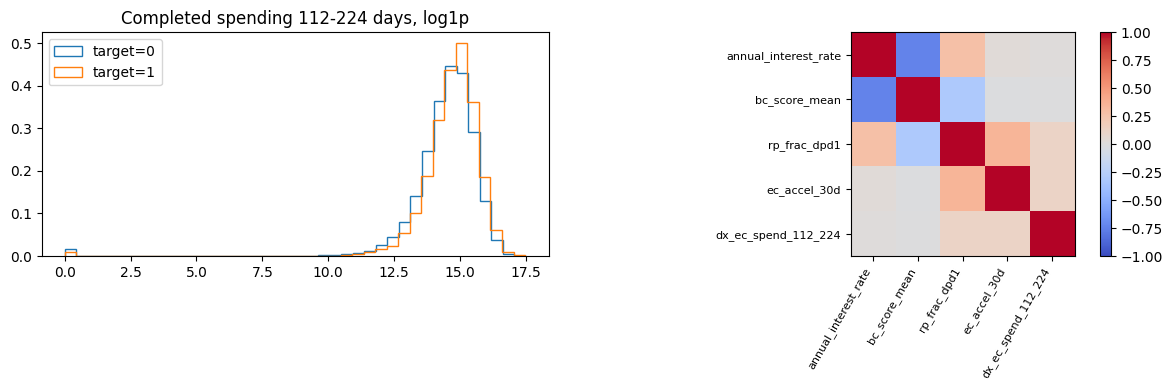

24

In [11]:
tr = VIEWS["raw"].filter(pl.col("is_train") == 1)
te = VIEWS["raw"].filter(pl.col("is_train") == 0)
train_ids = tr["application_id"].to_numpy().astype(str)
test_ids = te["application_id"].to_numpy().astype(str)
y = tr["target"].to_numpy().astype(np.int64)
history = tr["has_history"].to_numpy()
months = tr["decision_datetime"].dt.strftime("%Y-%m").to_numpy()
FOLDS = list(StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.FOLD_SEED).split(train_ids, y))
fold_id = np.full(len(y), -1, dtype=np.int8)
for fold, (ti, vi) in enumerate(FOLDS):
    assert not set(train_ids[ti]) & set(train_ids[vi])
    assert set(y[ti]) == set(y[vi]) == {0, 1}
    fold_id[vi] = fold
assert (fold_id >= 0).all() and not set(train_ids) & set(test_ids)
pd.DataFrame({"application_id": train_ids, "target": y, "fold": fold_id,
              "has_history": history, "decision_month": months}).to_csv(CFG.OUTPUT_DIR / "fold_manifest.csv", index=False)
FRAMES = {}
for name, frame in VIEWS.items():
    cols = sorted(c for c in frame.columns if c not in ID_COLS)
    cats = [c for c in BASE_CATS + ["rate_transition"] if c in cols]
    FRAMES[name] = (frame.filter(pl.col("is_train") == 1).select(cols).to_pandas(),
                    frame.filter(pl.col("is_train") == 0).select(cols).to_pandas(), cats)
numeric = [c for c in FRAMES["combined"][0] if c not in FRAMES["combined"][2]]
drift = pd.DataFrame([{"feature": c, "psi": psi(FRAMES["combined"][0][c], FRAMES["combined"][1][c])}
                      for c in numeric]).sort_values("psi", ascending=False)
drift.to_csv(CFG.OUTPUT_DIR / "feature_drift.csv", index=False)
print(drift.head(10).to_string(index=False))
print("Fixed folds:", np.bincount(fold_id), "bad rate:", y.mean())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for cls in (0, 1):
    values = FRAMES["combined"][0].loc[y == cls, "dx_ec_spend_112_224"].to_numpy(float)
    ax[0].hist(np.log1p(values[np.isfinite(values)]), bins=40, density=True, histtype="step", label=f"target={cls}")
ax[0].legend()
ax[0].set_title("Completed spending 112-224 days, log1p")
corr_cols = ["annual_interest_rate", "bc_score_mean", "rp_frac_dpd1",
             "ec_accel_30d", "dx_ec_spend_112_224"]
correlation = FRAMES["combined"][0][corr_cols].corr(method="spearman")
im = ax[1].imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
ax[1].set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right", fontsize=8)
ax[1].set_yticks(range(len(corr_cols)), corr_cols, fontsize=8)
fig.colorbar(im, ax=ax[1])
fig.tight_layout()
fig.savefig(FIG_DIR / "feature_diagnostics.png", dpi=130)
plt.show()
del T, apps, raw_features, spend_features, VIEWS, tr, te
gc.collect()

#### Insights

> Random stratified validation is supported by the overlapping train/test period, but small marginal PSI does not rule out conditional shift. Monthly OOF subsets below are stability diagnostics, not forward-time validation. The new spending feature remains a hypothesis until its paired model ablation is observed.

---

# Fold-local Preprocessing <a name="4"></a>

---

Interpolated empirical CDFs, missing indicators, categorical vocabularies, and embedding bins are fitted on each training fold only. Tree models retain raw numeric values and missingness. Unknown neural categories map to zero.

In [12]:
class FoldNumeric:
    def fit(self, values):
        x = np.asarray(values, dtype=np.float64)
        assert x.ndim == 2
        self.width = x.shape[1]
        self.refs = []
        self.missing = np.flatnonzero((~np.isfinite(x)).any(axis=0))
        for j in range(self.width):
            s = x[np.isfinite(x[:, j]), j]
            vals, counts = np.unique(s, return_counts=True)
            probs = (np.cumsum(counts) - 0.5 * counts) / max(len(s), 1)
            self.refs.append((vals, probs, max(len(s), 1)))
        return self

    def transform(self, values):
        x = np.asarray(values, dtype=np.float64)
        assert x.ndim == 2 and x.shape[1] == self.width
        unseen_missing = np.setdiff1d(np.flatnonzero((~np.isfinite(x)).any(axis=0)), self.missing)
        if len(unseen_missing):
            raise ValueError(f"New missingness in fit-complete columns: {unseen_missing.tolist()}")
        z = np.zeros(x.shape, dtype=np.float32)
        for j, (vals, probs, n) in enumerate(self.refs):
            if len(vals) == 0:
                continue
            observed = np.isfinite(x[:, j])
            u = np.interp(x[observed, j], vals, probs)
            z[observed, j] = scipy_special.ndtri(np.clip(u, 0.5 / n, 1 - 0.5 / n))
        flags = (~np.isfinite(x[:, self.missing])).astype(np.float32)
        result = np.column_stack([z, flags])
        assert np.isfinite(result).all()
        return result

def cat_vocabulary(frame, cats):
    return {c: sorted(frame[c].dropna().astype(str).unique().tolist()) for c in cats}

def cat_encode(frame, vocab):
    columns = []
    for c, values in vocab.items():
        mapping = {value: i + 1 for i, value in enumerate(values)}
        columns.append(frame[c].map(lambda value: mapping.get(str(value), 0) if pd.notna(value) else 0).to_numpy(np.int64))
    return np.column_stack(columns)

def tree_frames(view, ti, vi, native=True):
    X, Xt, cats = FRAMES[view]
    frames = [X.iloc[ti].copy(), X.iloc[vi].copy(), Xt.copy()]
    vocab = cat_vocabulary(frames[0], cats)
    for frame in frames:
        for c in cats:
            s = frame[c].astype("string")
            if native:
                frame[c] = pd.Categorical(s, categories=vocab[c])
            else:
                frame[c] = s.fillna("__MISSING__").astype(str)
    return frames, cats, vocab

def neural_frames(view, ti, vi):
    X, Xt, cats = FRAMES[view]
    nums = [c for c in X if c not in cats]
    train = X.iloc[ti][nums].to_numpy(np.float64)
    valid = X.iloc[vi][nums].to_numpy(np.float64)
    test = Xt[nums].to_numpy(np.float64)
    prep = FoldNumeric().fit(train)
    ztrain, zvalid, ztest = [prep.transform(a) for a in [train, valid, test]]
    keep = np.flatnonzero(np.ptp(ztrain, axis=0) > 0)
    assert len(keep) > 0
    vocab = cat_vocabulary(X.iloc[ti], cats)
    categoricals = [cat_encode(frame, vocab) for frame in [X.iloc[ti], X.iloc[vi], Xt]]
    state = {"numeric_columns": nums, "categorical_columns": cats, "refs": prep.refs,
             "missing": prep.missing, "keep": keep, "vocab": vocab,
             "cardinalities": [len(vocab[c]) + 1 for c in cats]}
    return [a[:, keep] for a in [ztrain, zvalid, ztest]], categoricals, state

toy = np.array([[0., np.nan], [0., 2.], [2., np.nan], [4., 3.]])
toy_prep = FoldNumeric().fit(toy)
toy_z = toy_prep.transform(toy)
assert np.isfinite(toy_z).all() and toy_z[0, 0] == toy_z[1, 0]
assert np.array_equal(toy_z[:, -1], [1, 0, 1, 0])
assert np.array_equal(toy_prep.transform(toy[[3, 0]]), toy_z[[3, 0]])
try:
    toy_prep.transform([[np.nan, 1.]])
except ValueError:
    pass
else:
    raise AssertionError("New missingness must fail explicitly.")
assert cat_encode(pd.DataFrame({"c": ["a", "unseen", None]}), {"c": ["a"]}).ravel().tolist() == [1, 0, 0]
print("Preprocessing self-checks passed.")

Preprocessing self-checks passed.


## Preprocessing Audit

Observed-value feature KS is compared before and after the fold-local transform. Matching feature KS validates this limited property; it does not establish a gain in model KS or guarantee preservation outside the fitted range.

          min  max
view              
combined  0.0  0.0
raw       0.0  0.0


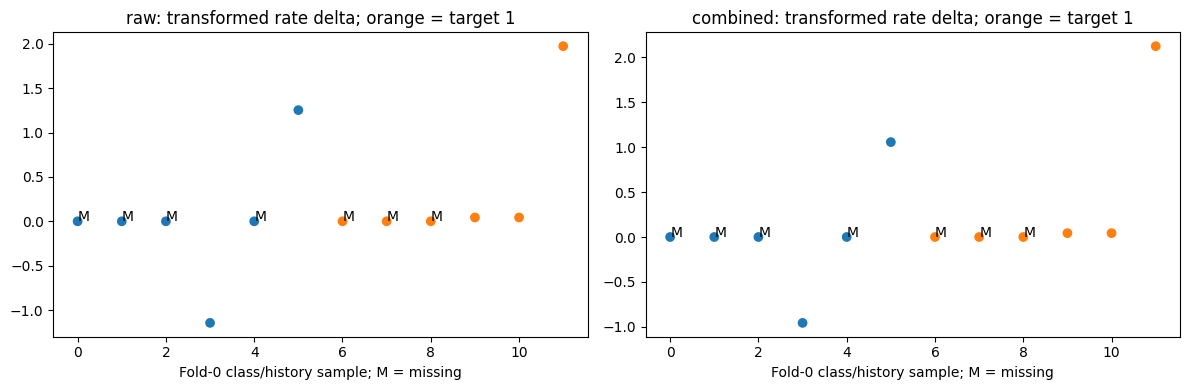

In [13]:
prep_rows = []
sample_rows = []
for view in ["raw", "combined"]:
    X, Xt, cats = FRAMES[view]
    nums = [c for c in X if c not in cats]
    for fold, (ti, vi) in enumerate(FOLDS):
        prep = FoldNumeric().fit(X.iloc[ti][nums].to_numpy(float))
        valid = X.iloc[vi][nums].to_numpy(float)
        z = prep.transform(valid)
        for j, col in enumerate(nums):
            observed = np.isfinite(valid[:, j])
            if np.unique(y[vi][observed]).size < 2:
                continue
            a, b = ks_score(y[vi][observed], valid[observed, j]), ks_score(y[vi][observed], z[observed, j])
            prep_rows.append({"view": view, "fold": fold, "feature": col, "raw_KS": a, "transformed_KS": b,
                              "delta": b - a})
        if fold == 0:
            for cls in [0, 1]:
                for hist in [0, 1]:
                    positions = np.flatnonzero((y[vi] == cls) & (history[vi] == hist))[:3]
                    for pos in positions:
                        for col in ["pv_rate_delta", "rp_frac_dpd1", "ec_accel_30d"]:
                            j = nums.index(col)
                            sample_rows.append({"view": view, "application_id": train_ids[vi[pos]],
                                                "target": cls, "has_history": hist, "feature": col,
                                                "raw": valid[pos, j], "transformed": float(z[pos, j]),
                                                "missing": not np.isfinite(valid[pos, j])})
prep_audit = pd.DataFrame(prep_rows)
prep_audit.to_csv(CFG.OUTPUT_DIR / "preprocessing_KS.csv", index=False)
samples = pd.DataFrame(sample_rows)
samples.to_csv(CFG.OUTPUT_DIR / "preprocessing_class_samples.csv", index=False)
print(prep_audit.groupby("view")["delta"].agg(["min", "max"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, view in zip(axes, ["raw", "combined"]):
    sample = samples[(samples["view"] == view) & (samples["feature"] == "pv_rate_delta")]
    colors = ["C1" if t else "C0" for t in sample["target"]]
    ax.scatter(np.arange(len(sample)), sample["transformed"], c=colors)
    for i, missing in enumerate(sample["missing"]):
        if missing:
            ax.text(i, sample.iloc[i]["transformed"], "M")
    ax.set_title(f"{view}: transformed rate delta; orange = target 1")
    ax.set_xlabel("Fold-0 class/history sample; M = missing")
fig.tight_layout()
fig.savefig(FIG_DIR / "preprocessing_samples.png", dpi=130)
plt.show()

#### Insights

> Every validation fold receives a transformation fitted without its rows. Missing-history flags remain distinct from genuine zeros. Constant transformed dimensions are dropped using training rows only before piecewise-linear embeddings; parent pricing features remain available in both views.

---

# Controlled Model Experiments <a name="5"></a>

---

All views share five fixed folds and two model seeds. Per-fold predictions, IDs, training duration, stopping iteration, and optional model checkpoints are saved immediately. Incomplete model families are never blended as if they had complete OOF coverage.

In [14]:
RESULTS = {}

def run_experiment(family, view, fit_one, gpu=None):
    name = f"{family}_{view}"
    out = CFG.OUTPUT_DIR / name
    out.mkdir(exist_ok=True)
    oof_sum = np.zeros(len(y), dtype=float)
    test_sum = np.zeros(len(test_ids), dtype=float)
    seen = np.zeros(len(y), dtype=int)
    rows = []
    for seed in CFG.SEEDS:
        for fold, (ti, vi) in enumerate(FOLDS):
            tag = out / f"seed{seed}_fold{fold}"
            start = time.monotonic()
            pv, pt, details = fit_one(view, ti, vi, seed, gpu, tag)
            check_prob(pv, len(vi))
            check_prob(pt, len(test_ids))
            assert roc_auc_score(y[vi], pv) > 0.5, f"Inverted ranking: {name}, fold {fold}"
            oof_sum[vi] += pv
            test_sum += pt
            seen[vi] += 1
            row = {"model": name, "seed": seed, "fold": fold, "KS": ks_score(y[vi], pv),
                   "AUC": roc_auc_score(y[vi], pv), "seconds": time.monotonic() - start, **details}
            rows.append(row)
            np.savez_compressed(str(tag) + "_predictions.npz", validation_ids=train_ids[vi],
                                validation_target=y[vi], validation_prediction=pv,
                                test_ids=test_ids, test_prediction=pt)
            pd.DataFrame(rows).to_csv(out / "fold_metrics.csv", index=False)
            print(name, seed, fold, {k: row[k] for k in ["KS", "AUC", "seconds"]}, flush=True)
            gc.collect()
            if gpu is not None:
                torch.cuda.empty_cache()
    assert np.all(seen == len(CFG.SEEDS))
    oof = oof_sum / len(CFG.SEEDS)
    test = test_sum / (len(CFG.SEEDS) * CFG.N_FOLDS)
    check_prob(oof, len(y))
    check_prob(test, len(test_ids))
    pd.DataFrame({"application_id": train_ids, "target": y, "fold": fold_id,
                  "prediction": oof}).to_csv(out / "oof.csv", index=False)
    pd.DataFrame({"application_id": test_ids, "prediction": test}).to_csv(out / "test.csv", index=False)
    return {"name": name, "oof": oof, "test": test, "fold_rows": rows}

def fit_lgb(view, ti, vi, seed, gpu, tag):
    (a, b, c), cats, vocab = tree_frames(view, ti, vi)
    train_set = lgb.Dataset(a, label=y[ti], categorical_feature=cats)
    valid_set = lgb.Dataset(b, label=y[vi], categorical_feature=cats, reference=train_set)
    model = lgb.train({**CFG.LGB_PARAMS, "seed": seed}, train_set,
                      num_boost_round=CFG.N_ROUNDS, valid_sets=[valid_set],
                      callbacks=[lgb.early_stopping(CFG.EARLY_STOP, verbose=False)])
    if CFG.SAVE_MODELS:
        model.save_model(str(tag) + ".txt", num_iteration=model.best_iteration)
        Path(str(tag) + "_categories.json").write_text(json.dumps(vocab))
    pd.DataFrame({"feature": model.feature_name(), "gain": model.feature_importance("gain")}).to_csv(
        str(tag) + "_importance.csv", index=False)
    return model.predict(b), model.predict(c), {"best_iteration": model.best_iteration}

def fit_xgb(view, ti, vi, seed, gpu, tag):
    (a, b, c), cats, vocab = tree_frames(view, ti, vi)
    da = xgb.DMatrix(a, label=y[ti], enable_categorical=True)
    db = xgb.DMatrix(b, label=y[vi], enable_categorical=True)
    dc = xgb.DMatrix(c, enable_categorical=True)
    model = xgb.train({**CFG.XGB_PARAMS, "seed": seed, "device": f"cuda:{gpu}"},
                      da, num_boost_round=CFG.N_ROUNDS, evals=[(db, "valid")],
                      early_stopping_rounds=CFG.EARLY_STOP, verbose_eval=False)
    limit = (0, model.best_iteration + 1)
    if CFG.SAVE_MODELS:
        model.save_model(str(tag) + ".ubj")
        Path(str(tag) + "_categories.json").write_text(json.dumps(vocab))
    return model.predict(db, iteration_range=limit), model.predict(dc, iteration_range=limit), {
        "best_iteration": model.best_iteration + 1}

def fit_cat(view, ti, vi, seed, gpu, tag):
    (a, b, c), cats, vocab = tree_frames(view, ti, vi, native=False)
    model = CatBoostClassifier(**CFG.CAT_PARAMS, random_seed=seed, devices=str(gpu))
    model.fit(Pool(a, y[ti], cat_features=cats), eval_set=Pool(b, y[vi], cat_features=cats))
    if CFG.SAVE_MODELS:
        model.save_model(str(tag) + ".cbm")
    return model.predict_proba(b)[:, 1], model.predict_proba(c)[:, 1], {
        "best_iteration": model.get_best_iteration() + 1}

## TabM Training

TabM uses fold-local Gaussian interpolation, per-column missing indicators, and training-only piecewise-linear bins. Each ensemble member receives its own binary cross-entropy loss; probabilities are averaged only for inference. The best validation-AUC checkpoint is retained within the fold time limit.

In [15]:
def tabm_predict(model, numeric, categorical, device):
    model.eval()
    predictions = []
    with torch.no_grad():
        for start in range(0, len(numeric), CFG.TABM_PRED_BATCH):
            end = start + CFG.TABM_PRED_BATCH
            xn = torch.as_tensor(numeric[start:end], dtype=torch.float32, device=device)
            xc = torch.as_tensor(categorical[start:end], dtype=torch.long, device=device)
            pred = torch.sigmoid(model(xn, xc).squeeze(-1).float()).mean(dim=1)
            predictions.append(pred.cpu().numpy())
    return np.concatenate(predictions)

def fit_tabm(view, ti, vi, seed, gpu, tag):
    seed_everything(seed)
    torch.set_num_threads(CFG.NUM_THREADS)
    device = torch.device(f"cuda:{gpu}")
    torch.cuda.set_device(device)
    start = time.monotonic()
    numeric, categorical, prep_state = neural_frames(view, ti, vi)
    bins = rtdl_num_embeddings.compute_bins(torch.from_numpy(numeric[0]), n_bins=CFG.TABM_BINS)
    embedding = rtdl_num_embeddings.PiecewiseLinearEmbeddings(
        bins, d_embedding=16, activation=False, version="B")
    model = tabm.TabM.make(n_num_features=numeric[0].shape[1],
                           cat_cardinalities=prep_state["cardinalities"], d_out=1,
                           num_embeddings=embedding, k=CFG.TABM_K,
                           d_block=CFG.TABM_WIDTH, n_blocks=2, dropout=0.1).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.TABM_LR, weight_decay=CFG.TABM_WD)
    xn = torch.as_tensor(numeric[0], dtype=torch.float32, device=device)
    xc = torch.as_tensor(categorical[0], dtype=torch.long, device=device)
    yt = torch.as_tensor(y[ti], dtype=torch.float32, device=device)
    best_auc, best_state, best_epoch, wait = -np.inf, None, -1, 0
    log_rows = []
    reason = "epoch_limit"
    for epoch in range(CFG.TABM_EPOCHS):
        model.train()
        loss_sum = 0.0
        for idx in torch.randperm(len(ti), device=device).split(CFG.TABM_BATCH):
            logits = model(xn[idx], xc[idx]).squeeze(-1)
            loss = torch.nn.functional.binary_cross_entropy_with_logits(
                logits, yt[idx, None].expand_as(logits))
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Nonfinite loss in {view}, seed {seed}, epoch {epoch}")
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            loss_sum += float(loss.detach()) * len(idx)
        pred = tabm_predict(model, numeric[1], categorical[1], device)
        auc = roc_auc_score(y[vi], pred)
        log_rows.append({"epoch": epoch + 1, "train_loss": loss_sum / len(ti),
                         "valid_AUC": auc, "valid_KS": ks_score(y[vi], pred),
                         "seconds": time.monotonic() - start})
        if auc > best_auc + 1e-6:
            best_auc, best_epoch, wait = auc, epoch + 1, 0
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            if CFG.SAVE_MODELS:
                torch.save({"state_dict": best_state, "bins": [b.cpu() for b in bins],
                            "numeric_width": numeric[0].shape[1],
                            "cardinalities": prep_state["cardinalities"], "epoch": best_epoch,
                            "k": CFG.TABM_K, "d_block": CFG.TABM_WIDTH,
                            "n_blocks": 2, "dropout": 0.1, "d_embedding": 16}, str(tag) + ".pt")
        else:
            wait += 1
        if wait >= CFG.TABM_PATIENCE:
            reason = "patience"
            break
        if time.monotonic() - start > CFG.TABM_FOLD_MINUTES * 60:
            reason = "time_limit"
            break
    assert best_state is not None
    model.load_state_dict(best_state)
    pv = tabm_predict(model, numeric[1], categorical[1], device)
    pt = tabm_predict(model, numeric[2], categorical[2], device)
    pd.DataFrame(log_rows).to_csv(str(tag) + "_epochs.csv", index=False)
    if CFG.SAVE_MODELS:
        with open(str(tag) + "_preprocessing.pkl", "wb") as handle:
            pickle.dump(prep_state, handle, protocol=pickle.HIGHEST_PROTOCOL)
    result = (pv, pt, {"best_iteration": best_epoch, "stop_reason": reason,
                       "numeric_width": numeric[0].shape[1]})
    del model, optimizer, xn, xc, yt, best_state, numeric, categorical
    torch.cuda.empty_cache()
    return result

## GPU Worker Preflight

The same GPU task and its dependency graph are sent through Loky before any model training. A small preprocessing and CUDA check catches worker deserialization failures early; SciPy special functions are accessed through their importable module rather than serialized as standalone notebook globals.

In [16]:
def gpu_queue(gpu, view, preflight=False):
    torch.cuda.set_device(gpu)
    torch.set_num_threads(CFG.NUM_THREADS)
    if preflight:
        # Resolve the ufunc through its importable module, not a pickled notebook global.
        np.testing.assert_allclose(
            scipy_special.ndtri(np.array([0.25, 0.5, 0.75])),
            [-0.6744897501960817, 0.0, 0.6744897501960817], atol=1e-12)
        sample = np.array([[0., np.nan], [0., 2.], [2., np.nan], [4., 3.]])
        transformed = FoldNumeric().fit(sample).transform(sample)
        assert transformed.shape == (4, 3) and np.isfinite(transformed).all()
        assert np.array_equal(transformed[:, -1], [1, 0, 1, 0])
        assert transformed[0, 0] == transformed[1, 0]
        assert ks_score([0, 0, 1, 1], [0., 0., 1., 1.]) == 1.0
        assert torch.ones(1, device=f"cuda:{gpu}").sum().item() == 1.0
        return {"gpu": gpu, "view": view, "preflight": "passed"}
    output = []
    for family, fit_fn in [("tabm", fit_tabm), ("xgb", fit_xgb), ("cat", fit_cat)]:
        output.append(run_experiment(family, view, fit_fn, gpu=gpu))
        gc.collect()
        torch.cuda.empty_cache()
    return output

with parallel_config(backend="loky", inner_max_num_threads=CFG.NUM_THREADS):
    worker_checks = Parallel(n_jobs=2, batch_size=1, verbose=10)(
        delayed(gpu_queue)(gpu, view, preflight=True)
        for gpu, view in [(0, "raw"), (1, "combined")])
assert worker_checks == [{"gpu": 0, "view": "raw", "preflight": "passed"},
                         {"gpu": 1, "view": "combined", "preflight": "passed"}]
print("GPU worker preflight:", worker_checks)

[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   2 out of   2 | elapsed:    4.1s finished


GPU worker preflight: [{'gpu': 0, 'view': 'raw', 'preflight': 'passed'}, {'gpu': 1, 'view': 'combined', 'preflight': 'passed'}]


## LightGBM Ablation

LightGBM uses the CPU while the later GPU queues run TabM, XGBoost, and CatBoost. The four feature views are trained without selecting features or tuning hyperparameters on the held-out rows. The resulting paired table separates the spending addition from the semantic representation change.

lgb_raw 42 0 {'KS': 0.5094341575044633, 'AUC': np.float64(0.8332113996057164), 'seconds': 26.62247077500001}
lgb_raw 42 1 {'KS': 0.514135073353061, 'AUC': np.float64(0.8393705202289772), 'seconds': 25.219994653000015}
lgb_raw 42 2 {'KS': 0.5006462770169945, 'AUC': np.float64(0.8286957430237888), 'seconds': 22.780396475999964}
lgb_raw 42 3 {'KS': 0.4967594647219457, 'AUC': np.float64(0.8294803792164203), 'seconds': 22.047676594999984}
lgb_raw 42 4 {'KS': 0.5306574471817, 'AUC': np.float64(0.8427099646611905), 'seconds': 25.66892242700004}
lgb_raw 7 0 {'KS': 0.49957098197280814, 'AUC': np.float64(0.8317846728195701), 'seconds': 22.848575651000033}
lgb_raw 7 1 {'KS': 0.513170603436953, 'AUC': np.float64(0.8396815175381743), 'seconds': 24.392786579000017}
lgb_raw 7 2 {'KS': 0.49972771974712044, 'AUC': np.float64(0.8287360470228976), 'seconds': 22.785113461000037}
lgb_raw 7 3 {'KS': 0.5004072941639075, 'AUC': np.float64(0.830354418933077), 'seconds': 22.890825734000032}
lgb_raw 7 4 {'KS': 0

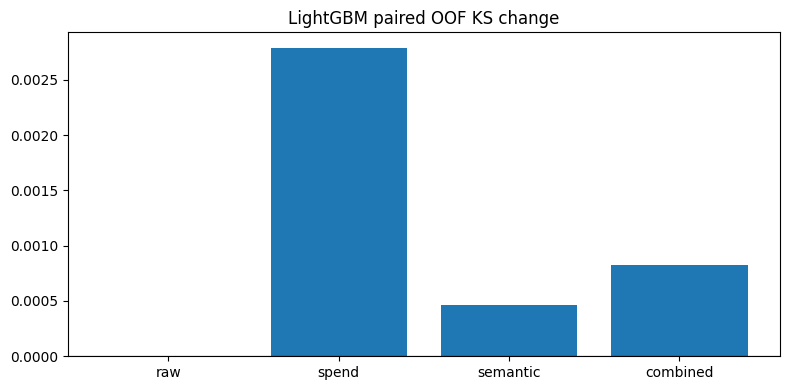

In [17]:
for view in ["raw", "spend", "semantic", "combined"]:
    result = run_experiment("lgb", view, fit_lgb)
    RESULTS[result["name"]] = result

ablation_rows = []
baseline = RESULTS["lgb_raw"]["oof"]
for view in ["raw", "spend", "semantic", "combined"]:
    pred = RESULTS[f"lgb_{view}"]["oof"]
    deltas = [ks_score(y[vi], pred[vi]) - ks_score(y[vi], baseline[vi]) for _, vi in FOLDS]
    ablation_rows.append({"view": view, "OOF_KS": ks_score(y, pred),
                         "delta_vs_raw": ks_score(y, pred) - ks_score(y, baseline),
                         "positive_folds": int(np.sum(np.asarray(deltas) > 0)),
                         **{f"fold{k}_delta": delta for k, delta in enumerate(deltas)}})
ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(CFG.OUTPUT_DIR / "lgb_ablation.csv", index=False)
print(ablation.to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(ablation["view"], ablation["delta_vs_raw"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("LightGBM paired OOF KS change")
fig.tight_layout()
fig.savefig(FIG_DIR / "lgb_ablation.png", dpi=130)
plt.show()

#### Insights

> Feature KS and residual association motivated these experiments but did not establish their outcome. Read the measured OOF delta together with the per-fold signs. Existing EDA reused these labels, so the ablation is not a fresh independent confirmation.

## Two-GPU Execution

Each process owns one physical GPU and runs its queue sequentially, avoiding simultaneous models competing for one card. Separate processes also isolate neural random-number state; no CPU fallback silently substitutes a different experiment.

In [18]:
gpu_start = time.monotonic()
with parallel_config(backend="loky", inner_max_num_threads=CFG.NUM_THREADS):
    queues = Parallel(n_jobs=2, batch_size=1, verbose=10)(
        delayed(gpu_queue)(gpu, view) for gpu, view in [(0, "raw"), (1, "combined")])
for queue in queues:
    for result in queue:
        RESULTS[result["name"]] = result
expected = {f"{family}_{view}" for family in ["lgb", "tabm", "xgb", "cat"]
            for view in ["raw", "combined"]} | {"lgb_spend", "lgb_semantic"}
assert set(RESULTS) == expected
print("Both GPU queues completed in minutes:", (time.monotonic() - gpu_start) / 60)
metrics = pd.DataFrame([
    {"model": name, "OOF_KS": ks_score(y, r["oof"]), "signed_KS": signed_ks(y, r["oof"]),
     "AUC": roc_auc_score(y, r["oof"]),
     "thin_KS": ks_score(y[history == 0], r["oof"][history == 0]),
     "history_KS": ks_score(y[history == 1], r["oof"][history == 1])}
    for name, r in RESULTS.items()]).sort_values("OOF_KS", ascending=False)
metrics.to_csv(CFG.OUTPUT_DIR / "model_metrics.csv", index=False)
print(metrics.to_string(index=False))

[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
/usr/local/lib/python3.13/dist-packages/rtdl_num_embeddings.py:340: UserWarning: The 142-th feature has just two bin edges, which means only one bin. Strictly speaking, using a single bin for the piecewise-linear encoding should not break anything, but it is the same as using sklearn.preprocessing.MinMaxScaler
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/rtdl_num_embeddings.py:340: UserWarning: The 141-th feature has just two bin edges, which means only one bin. Strictly speaking, using a single bin for the piecewise-linear encoding should not break anything, but it is the same as using sklearn.preprocessing.MinMaxScaler
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/rtdl_num_embeddings.py:340: UserWarning: The 211-th feature has just two bin edges, which means only one bin. Strictly speaking, using a single bin for the piecewise-linear encoding should not break anything, but it is the same

tabm_raw 42 0 {'KS': 0.508534382680776, 'AUC': np.float64(0.834155391438135), 'seconds': 144.63346979400012}


/usr/local/lib/python3.13/dist-packages/rtdl_num_embeddings.py:340: UserWarning: The 141-th feature has just two bin edges, which means only one bin. Strictly speaking, using a single bin for the piecewise-linear encoding should not break anything, but it is the same as using sklearn.preprocessing.MinMaxScaler
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/rtdl_num_embeddings.py:340: UserWarning: The 210-th feature has just two bin edges, which means only one bin. Strictly speaking, using a single bin for the piecewise-linear encoding should not break anything, but it is the same as using sklearn.preprocessing.MinMaxScaler
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/rtdl_num_embeddings.py:340: UserWarning: The 211-th feature has just two bin edges, which means only one bin. Strictly speaking, using a single bin for the piecewise-linear encoding should not break anything, but it is the same as using sklearn.preprocessing.MinMaxScaler
  warnings.warn(
/usr/local/li

tabm_combined 42 0 {'KS': 0.5103897579320944, 'AUC': np.float64(0.8347967337152171), 'seconds': 150.69620920400007}


/usr/local/lib/python3.13/dist-packages/rtdl_num_embeddings.py:340: UserWarning: The 142-th feature has just two bin edges, which means only one bin. Strictly speaking, using a single bin for the piecewise-linear encoding should not break anything, but it is the same as using sklearn.preprocessing.MinMaxScaler
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/rtdl_num_embeddings.py:340: UserWarning: The 211-th feature has just two bin edges, which means only one bin. Strictly speaking, using a single bin for the piecewise-linear encoding should not break anything, but it is the same as using sklearn.preprocessing.MinMaxScaler
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/rtdl_num_embeddings.py:340: UserWarning: The 212-th feature has just two bin edges, which means only one bin. Strictly speaking, using a single bin for the piecewise-linear encoding should not break anything, but it is the same as using sklearn.preprocessing.MinMaxScaler
  warnings.warn(
/usr/local/li

...

cat_combined 7 4 {'KS': 0.5343676831984987, 'AUC': np.float64(0.8420569554735173), 'seconds': 57.41828466700008}
cat_raw 7 3 {'KS': 0.4918187414071448, 'AUC': np.float64(0.8297379149841663), 'seconds': 35.90586598300024}


Default metric period is 5 because AUC is/are not implemented for GPU


cat_raw 7 4 {'KS': 0.5266383942284174, 'AUC': np.float64(0.8414259363463366), 'seconds': 48.23877485899993}


[Parallel(n_jobs=2)]: Done   2 out of   2 | elapsed: 38.9min finished


Both GPU queues completed in minutes: 38.92132478444999
        model   OOF_KS  signed_KS      AUC  thin_KS  history_KS
tabm_combined 0.509759   0.509759 0.837604 0.473025    0.525157
    lgb_spend 0.509747   0.509747 0.835519 0.472058    0.522357
     tabm_raw 0.509498   0.509498 0.837113 0.469946    0.524800
 xgb_combined 0.509090   0.509090 0.835586 0.471283    0.522939
 cat_combined 0.508093   0.508093 0.835135 0.473182    0.522223
 lgb_combined 0.507787   0.507787 0.835427 0.469699    0.520604
      cat_raw 0.507753   0.507753 0.835240 0.474139    0.521152
 lgb_semantic 0.507418   0.507418 0.835481 0.469626    0.522358
      xgb_raw 0.507207   0.507207 0.835474 0.470230    0.521755
      lgb_raw 0.506958   0.506958 0.835236 0.471813    0.521100


#### Insights

> Compare raw and combined within the same model family before attributing a change to the model architecture. GPU-to-GPU numerical differences and time-limited TabM stopping are recorded limitations. The v4 raw baseline uses corrected fold-local preprocessing and two seeds, so it is not an exact rerun of the old v3 ensemble.

---

# Ensemble and Stability <a name="6"></a>

---

Prespecified weights favor the two strongest earlier supervised families without optimizing dozens of weights on the same OOF labels. The challenger averages the raw and combined rank ensembles equally, shrinking reliance on the new features.

     blend       KS  signed_KS      AUC
  baseline 0.511407   0.511407 0.837616
  combined 0.511897   0.511897 0.837887
challenger 0.511276   0.511276 0.837883
{
  "selected": "baseline",
  "challenger_minus_baseline": -0.00013112517570657012,
  "paired_fixed_prediction_CI95": [
    -0.0015877902334727578,
    0.0017114582744800959
  ],
  "fold_deltas": [
    -0.0017373327943814854,
    0.003575577759131532,
    0.0012850758378221139,
    0.0024024792967491937,
    0.0020732368100052634
  ],
  "segment_deltas": {
    "0": 0.00020504343731786445,
    "1": 0.00020945990736831455
  },
  "family_weights": {
    "lgb": 0.4,
    "tabm": 0.45,
    "xgb": 0.1,
    "cat": 0.05
  },
  "challenger_combined_fraction": 0.5,
  "interpretation": "Conservative OOF selection heuristic, not an unbiased post-selection estimate or private-KS guarantee."
}


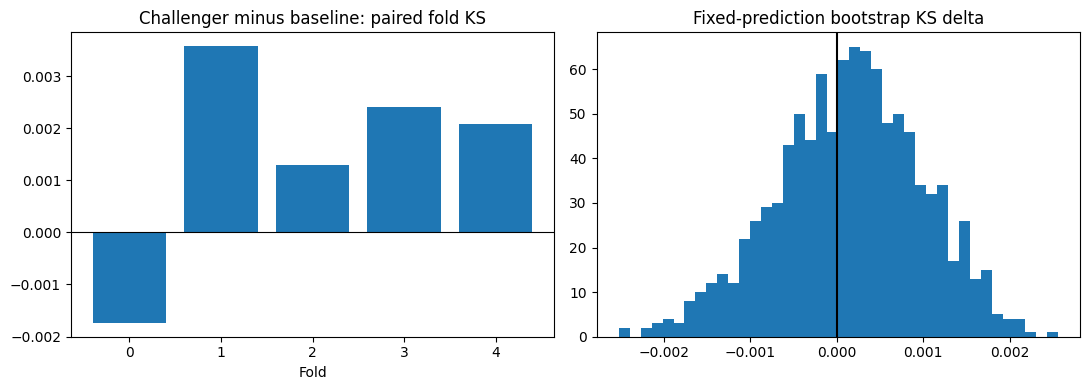

In [19]:
def ranking(pred):
    return rankdata(np.asarray(pred), method="average") / (len(pred) + 1.0)

def fixed_blend(view):
    oof = sum(weight * ranking(RESULTS[f"{family}_{view}"]["oof"])
              for family, weight in CFG.FAMILY_WEIGHTS.items())
    test = sum(weight * ranking(RESULTS[f"{family}_{view}"]["test"])
               for family, weight in CFG.FAMILY_WEIGHTS.items())
    return {"oof": oof, "test": test}

BLENDS = {"baseline": fixed_blend("raw"), "combined": fixed_blend("combined")}
BLENDS["challenger"] = {part: 0.5 * BLENDS["baseline"][part] + 0.5 * BLENDS["combined"][part]
                        for part in ["oof", "test"]}
blend_metrics = pd.DataFrame([
    {"blend": name, "KS": ks_score(y, result["oof"]), "signed_KS": signed_ks(y, result["oof"]),
     "AUC": roc_auc_score(y, result["oof"])}
    for name, result in BLENDS.items()])
blend_metrics.to_csv(CFG.OUTPUT_DIR / "blend_metrics.csv", index=False)
print(blend_metrics.to_string(index=False))

def paired_bootstrap(a, b):
    rng = np.random.default_rng(CFG.SEED + 900)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    deltas = np.empty(CFG.BOOTSTRAPS)
    for i in range(CFG.BOOTSTRAPS):
        idx = np.r_[rng.choice(pos, len(pos), replace=True), rng.choice(neg, len(neg), replace=True)]
        deltas[i] = ks_score(y[idx], b[idx]) - ks_score(y[idx], a[idx])
    return deltas

base, challenger = BLENDS["baseline"]["oof"], BLENDS["challenger"]["oof"]
deltas = paired_bootstrap(base, challenger)
lo, hi = np.quantile(deltas, [0.025, 0.975])
gain = ks_score(y, challenger) - ks_score(y, base)
fold_deltas = [ks_score(y[vi], challenger[vi]) - ks_score(y[vi], base[vi]) for _, vi in FOLDS]
segment_deltas = {str(h): ks_score(y[history == h], challenger[history == h])
                  - ks_score(y[history == h], base[history == h]) for h in [0, 1]}
promote = (gain >= CFG.MIN_GAIN and lo > 0
           and sum(d > 0 for d in fold_deltas) >= CFG.MIN_POSITIVE_FOLDS
           and min(segment_deltas.values()) >= -CFG.MAX_SEGMENT_DROP)
SELECTED = "challenger" if promote else "baseline"
selection = {"selected": SELECTED, "challenger_minus_baseline": float(gain),
             "paired_fixed_prediction_CI95": [float(lo), float(hi)],
             "fold_deltas": [float(v) for v in fold_deltas], "segment_deltas": segment_deltas,
             "family_weights": CFG.FAMILY_WEIGHTS, "challenger_combined_fraction": 0.5,
             "interpretation": "Conservative OOF selection heuristic, not an unbiased post-selection estimate or private-KS guarantee."}
(CFG.OUTPUT_DIR / "selection.json").write_text(json.dumps(selection, indent=2))
print(json.dumps(selection, indent=2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(np.arange(CFG.N_FOLDS), fold_deltas)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Challenger minus baseline: paired fold KS")
axes[0].set_xlabel("Fold")
axes[1].hist(deltas, bins=40)
axes[1].axvline(0, color="black")
axes[1].set_title("Fixed-prediction bootstrap KS delta")
fig.tight_layout()
fig.savefig(FIG_DIR / "paired_ensemble.png", dpi=130)
plt.show()

## Segment, Month, and Sampling Checks

The selected ensemble is evaluated across history groups and decision months. Public/private simulations use several assumed public fractions because the actual split size is unknown; competition score weights are not sample fractions.

     blend   group value     n  positives       KS  signed_KS
  baseline history     0 21000       2461 0.472876   0.472876
  baseline history     1 49000       7046 0.525222   0.525222
  combined history     0 21000       2461 0.476404   0.476404
  combined history     1 49000       7046 0.526080   0.526080
challenger history     0 21000       2461 0.473082   0.473082
challenger history     1 49000       7046 0.525431   0.525431
 assumed_public_share  public_n  private_n  public_median  public_p025  public_p975  private_median  absolute_gap_p95
                  0.1      3000      27000       0.522945     0.484801     0.561029        0.512220          0.044457
                  0.3      9000      21000       0.515784     0.494848     0.538712        0.512281          0.031981
                  0.5     15000      15000       0.512524     0.495200     0.529650        0.513578          0.027534


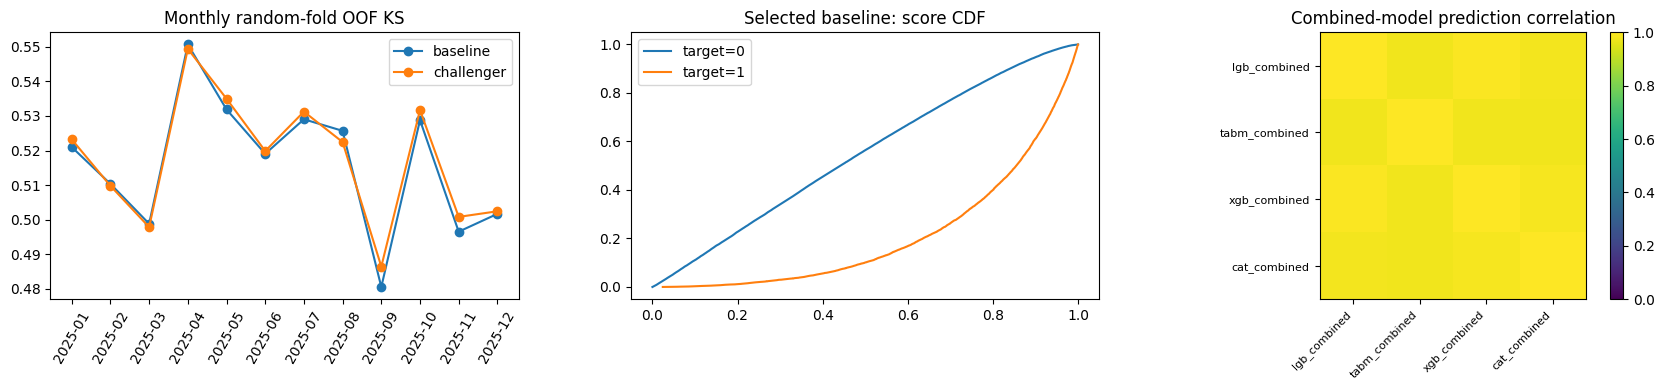

In [20]:
stability = []
for name, result in BLENDS.items():
    for group, labels in [("fold", fold_id), ("history", history), ("month", months)]:
        for value in sorted(set(labels)):
            mask = labels == value
            stability.append({"blend": name, "group": group, "value": str(value),
                              "n": int(mask.sum()), "positives": int(y[mask].sum()),
                              "KS": ks_score(y[mask], result["oof"][mask]),
                              "signed_KS": signed_ks(y[mask], result["oof"][mask])})
stability = pd.DataFrame(stability)
stability.to_csv(CFG.OUTPUT_DIR / "KS_stability.csv", index=False)
print(stability[stability["group"] == "history"].to_string(index=False))
simulations = []
rng = np.random.default_rng(CFG.SEED + 901)
pred = BLENDS[SELECTED]["oof"]
n_test = min(len(test_ids), len(y))
for share in CFG.PUBLIC_SHARES:
    pub_n = int(n_test * share)
    public_scores, private_scores = [], []
    for _ in range(CFG.SIMULATIONS):
        idx = rng.choice(len(y), n_test, replace=False)
        public_scores.append(ks_score(y[idx[:pub_n]], pred[idx[:pub_n]]))
        private_scores.append(ks_score(y[idx[pub_n:]], pred[idx[pub_n:]]))
    public_scores, private_scores = np.array(public_scores), np.array(private_scores)
    simulations.append({"assumed_public_share": share, "public_n": pub_n, "private_n": n_test - pub_n,
                        "public_median": np.nanmedian(public_scores),
                        "public_p025": np.nanquantile(public_scores, .025),
                        "public_p975": np.nanquantile(public_scores, .975),
                        "private_median": np.nanmedian(private_scores),
                        "absolute_gap_p95": np.nanquantile(np.abs(public_scores - private_scores), .95)})
simulations = pd.DataFrame(simulations)
simulations.to_csv(CFG.OUTPUT_DIR / "sampling_scenarios.csv", index=False)
print(simulations.to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for name in ["baseline", "challenger"]:
    rows = stability[(stability["blend"] == name) & (stability["group"] == "month")].sort_values("value")
    axes[0].plot(rows["value"], rows["KS"], marker="o", label=name)
axes[0].tick_params(axis="x", rotation=60)
axes[0].set_title("Monthly random-fold OOF KS")
axes[0].legend()
for cls in [0, 1]:
    values = np.sort(pred[y == cls])
    axes[1].plot(values, np.arange(1, len(values) + 1) / len(values), label=f"target={cls}")
axes[1].set_title(f"Selected {SELECTED}: score CDF")
axes[1].legend()
model_names = [f"{family}_combined" for family in CFG.FAMILY_WEIGHTS]
prediction_corr = pd.DataFrame({name: RESULTS[name]["oof"] for name in model_names}).corr(method="spearman")
im = axes[2].imshow(prediction_corr, vmin=0, vmax=1, cmap="viridis")
axes[2].set_xticks(range(len(model_names)), model_names, rotation=45, ha="right", fontsize=8)
axes[2].set_yticks(range(len(model_names)), model_names, fontsize=8)
axes[2].set_title("Combined-model prediction correlation")
fig.colorbar(im, ax=axes[2])
fig.tight_layout()
fig.savefig(FIG_DIR / "KS_stability.png", dpi=130)
plt.show()

#### Insights

> A narrow fixed-prediction bootstrap interval does not include retraining variability, earlier feature selection, or public/private distribution changes. Monthly subset KS is not an out-of-time test. The submission gate limits reliance on an inconsistent candidate; it cannot guarantee a small leaderboard gap.

---

# Submission and Reproducibility <a name="7"></a>

---

The main submission follows the recorded selection rule. Baseline, combined, and challenger files are retained for review; no upload or leaderboard probing is performed. Rank blends are bounded risk scores for the KS task, not calibrated default probabilities.

In [21]:
def write_submission(prediction, path):
    check_prob(prediction, len(test_ids))
    frame = pd.DataFrame({"application_id": test_ids, "default_probability": prediction})
    ordered = sample_sub.select("application_id").to_pandas().merge(frame, on="application_id",
                                                                   how="left", validate="one_to_one")
    assert len(ordered) == len(test_ids) and ordered["application_id"].is_unique
    assert set(ordered["application_id"]) == set(test_ids)
    assert ordered.columns.tolist() == ["application_id", "default_probability"]
    check_prob(ordered["default_probability"].to_numpy(), len(test_ids))
    ordered.to_csv(path, index=False)
    return ordered

for name, result in BLENDS.items():
    write_submission(result["test"], CFG.OUTPUT_DIR / f"submission_{name}.csv")
    pd.DataFrame({"application_id": train_ids, "target": y, "fold": fold_id,
                  "prediction": result["oof"]}).to_csv(CFG.OUTPUT_DIR / f"oof_{name}.csv", index=False)
submission = write_submission(BLENDS[SELECTED]["test"], Path("/kaggle/working/submission.csv"))
summary = {"selected": SELECTED, "OOF_KS": ks_score(y, BLENDS[SELECTED]["oof"]),
           "OOF_AUC": roc_auc_score(y, BLENDS[SELECTED]["oof"]),
           "rows": len(submission), "elapsed_minutes": (time.monotonic() - RUN_START) / 60,
           "main_submission": "/kaggle/working/submission.csv",
           "public_KS": None, "private_KS": None, "training_seeds": CFG.SEEDS,
           "fold_seed": CFG.FOLD_SEED, "n_folds": CFG.N_FOLDS}
(CFG.OUTPUT_DIR / "run_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
print(submission.head().to_string(index=False))
print("Inspect lgb_ablation.csv, model_metrics.csv, selection.json and KS_stability.csv before submitting.")

{
  "selected": "baseline",
  "OOF_KS": 0.5114068357000261,
  "OOF_AUC": 0.837616223664805,
  "rows": 30000,
  "elapsed_minutes": 57.52185859043333,
  "main_submission": "/kaggle/working/submission.csv",
  "public_KS": null,
  "private_KS": null,
  "training_seeds": [
    42,
    7
  ],
  "fold_seed": 42,
  "n_folds": 5
}
    application_id  default_probability
A_a4f0104b642c9af0             0.089265
A_08d66c9e92ab0b7d             0.554308
A_9a520f63bdee8684             0.925342
A_7ccd9c4aa0f036b1             0.026906
A_559cc08a9c7fa719             0.246720
Inspect lgb_ablation.csv, model_metrics.csv, selection.json and KS_stability.csv before submitting.


#### Insights

> If the challenger fails the prespecified consistency checks, submission.csv uses the corrected raw baseline. This is an explicit outcome of the experiment, not evidence that all new features are useless. Public/private scores remain unknown until evaluated by the competition.

## References

The model implementations follow the official [TabM repository](https://github.com/yandex-research/tabm), [numerical embeddings library](https://github.com/yandex-research/rtdl-num-embeddings), [LightGBM training API](https://lightgbm.readthedocs.io/en/v4.6.0/pythonapi/lightgbm.train.html), [XGBoost GPU guide](https://xgboost.readthedocs.io/en/release_3.0.0/gpu/index.html), and [CatBoost GPU settings](https://catboost.ai/docs/en/references/training-parameters/processing-unit). Feature hypotheses and preprocessing choices originate from this project's deep EDA, not benchmark rankings.